# How predictor dependence limits bagging

The accuracy of an odd-sized majority vote is the chance that more than half of its independent voters are correct:

$$
A_N(p)=\Pr\!\left(K>\frac{N}{2}\right)
=\sum_{k=(N+1)/2}^{N}{N\choose k}p^k(1-p)^{N-k},
\qquad K\sim\operatorname{Binomial}(N,p),
\qquad N\text{ odd}.
$$

Here, $N$ is the odd number of voters; $p$ is each voter's common probability of being correct; $K$ is the number of correct votes. $A_N(p)$ is ensemble accuracy; $k$ is a possible count of correct votes; ${N\choose k}$ counts vote arrangements; $\Pr$ denotes probability.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, adjusted_rand_score, silhouette_samples
from sklearn.utils import check_random_state

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib
import io
import zipfile

DATA_URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip"
DATA_DIR = ROOT / "data" / "public" / "ken_french"
DATA_PATH = ensure_dataset(ROOT, "french_49_industries")
EXPECTED_DATA_HASH = "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == EXPECTED_DATA_HASH
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode("latin1").splitlines()
header_row = next(index for index, line in enumerate(public_lines) if line.startswith(",Agric"))
end_row = next(index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip())
raw = pd.read_csv(io.StringIO("\n".join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: "Date"})
raw["Date"] = pd.to_datetime(raw["Date"].astype(str), format="%Y%m%d")
raw = raw.set_index("Date").replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc["2019-01-01":"2025-12-31"].dropna().copy()

from RiskLabAI.cluster.clustering import cluster_k_means_base, cluster_k_means_top, random_block_correlation
from RiskLabAI.ensemble.bagging_classifier_accuracy import bagging_classifier_accuracy
from RiskLabAI.ensemble.empirical_bagging_accuracy import BaggingClassifierAccuracy, calculate_bootstrap_accuracy

warnings.filterwarnings("ignore", message="X has feature names")

FIGURES = ROOT / "outputs" / "figures" / "15_predictor_clustering"
TABLES = ROOT / "outputs" / "tables" / "15_predictor_clustering"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

selected_features = ["Food", "Beer", "Hshld", "Oil", "Coal", "Mines", "Hardw", "Softw", "Chips", "Banks", "Insur", "Fin"]
trailing_returns = industry_returns[selected_features].rolling(5).sum().shift(1)
market_direction = (industry_returns.mean(axis=1) > 0).astype(int).rename("Market direction")
public_frame = pd.concat([trailing_returns, market_direction], axis=1).dropna()
public_x = public_frame[selected_features]
public_y = public_frame["Market direction"]
split_index = int(len(public_x) * 0.70)
public_x_train = public_x.iloc[:split_index]
public_y_train = public_y.iloc[:split_index]
public_x_test = public_x.iloc[split_index:]
public_y_test = public_y.iloc[split_index:]

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_cluster_table(frame, stem, caption, label):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    summary_columns = [column for column in frame.columns if column != "Industries"]
    headings = {
        "Cluster": "Cluster",
        "Size": "Size",
        "Mean silhouette": r"Mean $s$",
        "Minimum silhouette": r"Minimum $s$",
        "Quality": "Quality",
        "Mean within correlation": r"Mean $\rho$",
        "Mean within-cluster co-membership": "Mean joining frequency",
    }
    lines = [
        r"\begin{table}[H]",
        f"\\caption{{{caption}}}",
        f"\\label{{{label}}}",
        r"\centering",
        r"\small",
        r"\begin{tabular}{@{}" + "r" * len(summary_columns) + r"@{}}",
        r"\toprule",
        " & ".join(headings[column] for column in summary_columns) + r" \\",
        r"\midrule",
    ]
    for _, row in frame.iterrows():
        values = []
        for column in summary_columns:
            value = row[column]
            if column in {"Cluster", "Size"}:
                values.append(str(int(value)))
            else:
                values.append(f"{float(value):.6f}")
        lines.append(" & ".join(values) + r" \\")
    lines.extend([
        r"\bottomrule",
        r"\end{tabular}",
        r"\par\medskip",
        r"\begin{tabular}{@{}r p{0.82\textwidth}@{}}",
        r"\toprule",
        r"Cluster & Industries \\",
        r"\midrule",
    ])
    for _, row in frame.iterrows():
        members = str(row["Industries"]).replace("&", r"\&")
        lines.append(f"{int(row['Cluster'])} & {members}" + r" \\")
    lines.extend([r"\bottomrule", r"\end{tabular}", r"\end{table}"])
    (TABLES / f"{stem}.tex").write_text("\n".join(lines), encoding="utf-8")

def labels_from_clusters(columns, clusters):
    labels = pd.Series(index=columns, dtype="int64")
    for cluster_id, members in clusters.items():
        labels.loc[members] = int(cluster_id)
    return labels.astype(int)

def mean_within_correlation(correlation, members):
    if len(members) < 2:
        return 1.0
    block = correlation.loc[members, members].to_numpy()
    return block[np.triu_indices(len(members), 1)].mean()
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Independent Majority Voting

,Field,Value
0,Archive,49_Industry_Portfolios_daily_CSV.zip
1,Provider,Kenneth R. French Data Library
2,Provider database vintage,202608 CRSP database
3,Return type,Daily value-weighted return
4,Analysis start,2019-01-02
5,Analysis end,2025-12-31
6,Daily observations,"1,760"
7,Industry portfolios,49
8,Archive SHA256,8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71...


,Voters,Single-voter accuracy,Ensemble accuracy,Change
0,1,0.40,0.400000,0
1,1,0.50,0.500000,0
2,1,0.55,0.550000,0
3,1,0.60,0.600000,0
4,1,0.70,0.700000,0
15,11,0.40,0.246502,-0.153498
16,11,0.50,0.500000,0
17,11,0.55,0.633123,0.083123
18,11,0.60,0.753498,0.153498
19,11,0.70,0.921775,0.221775


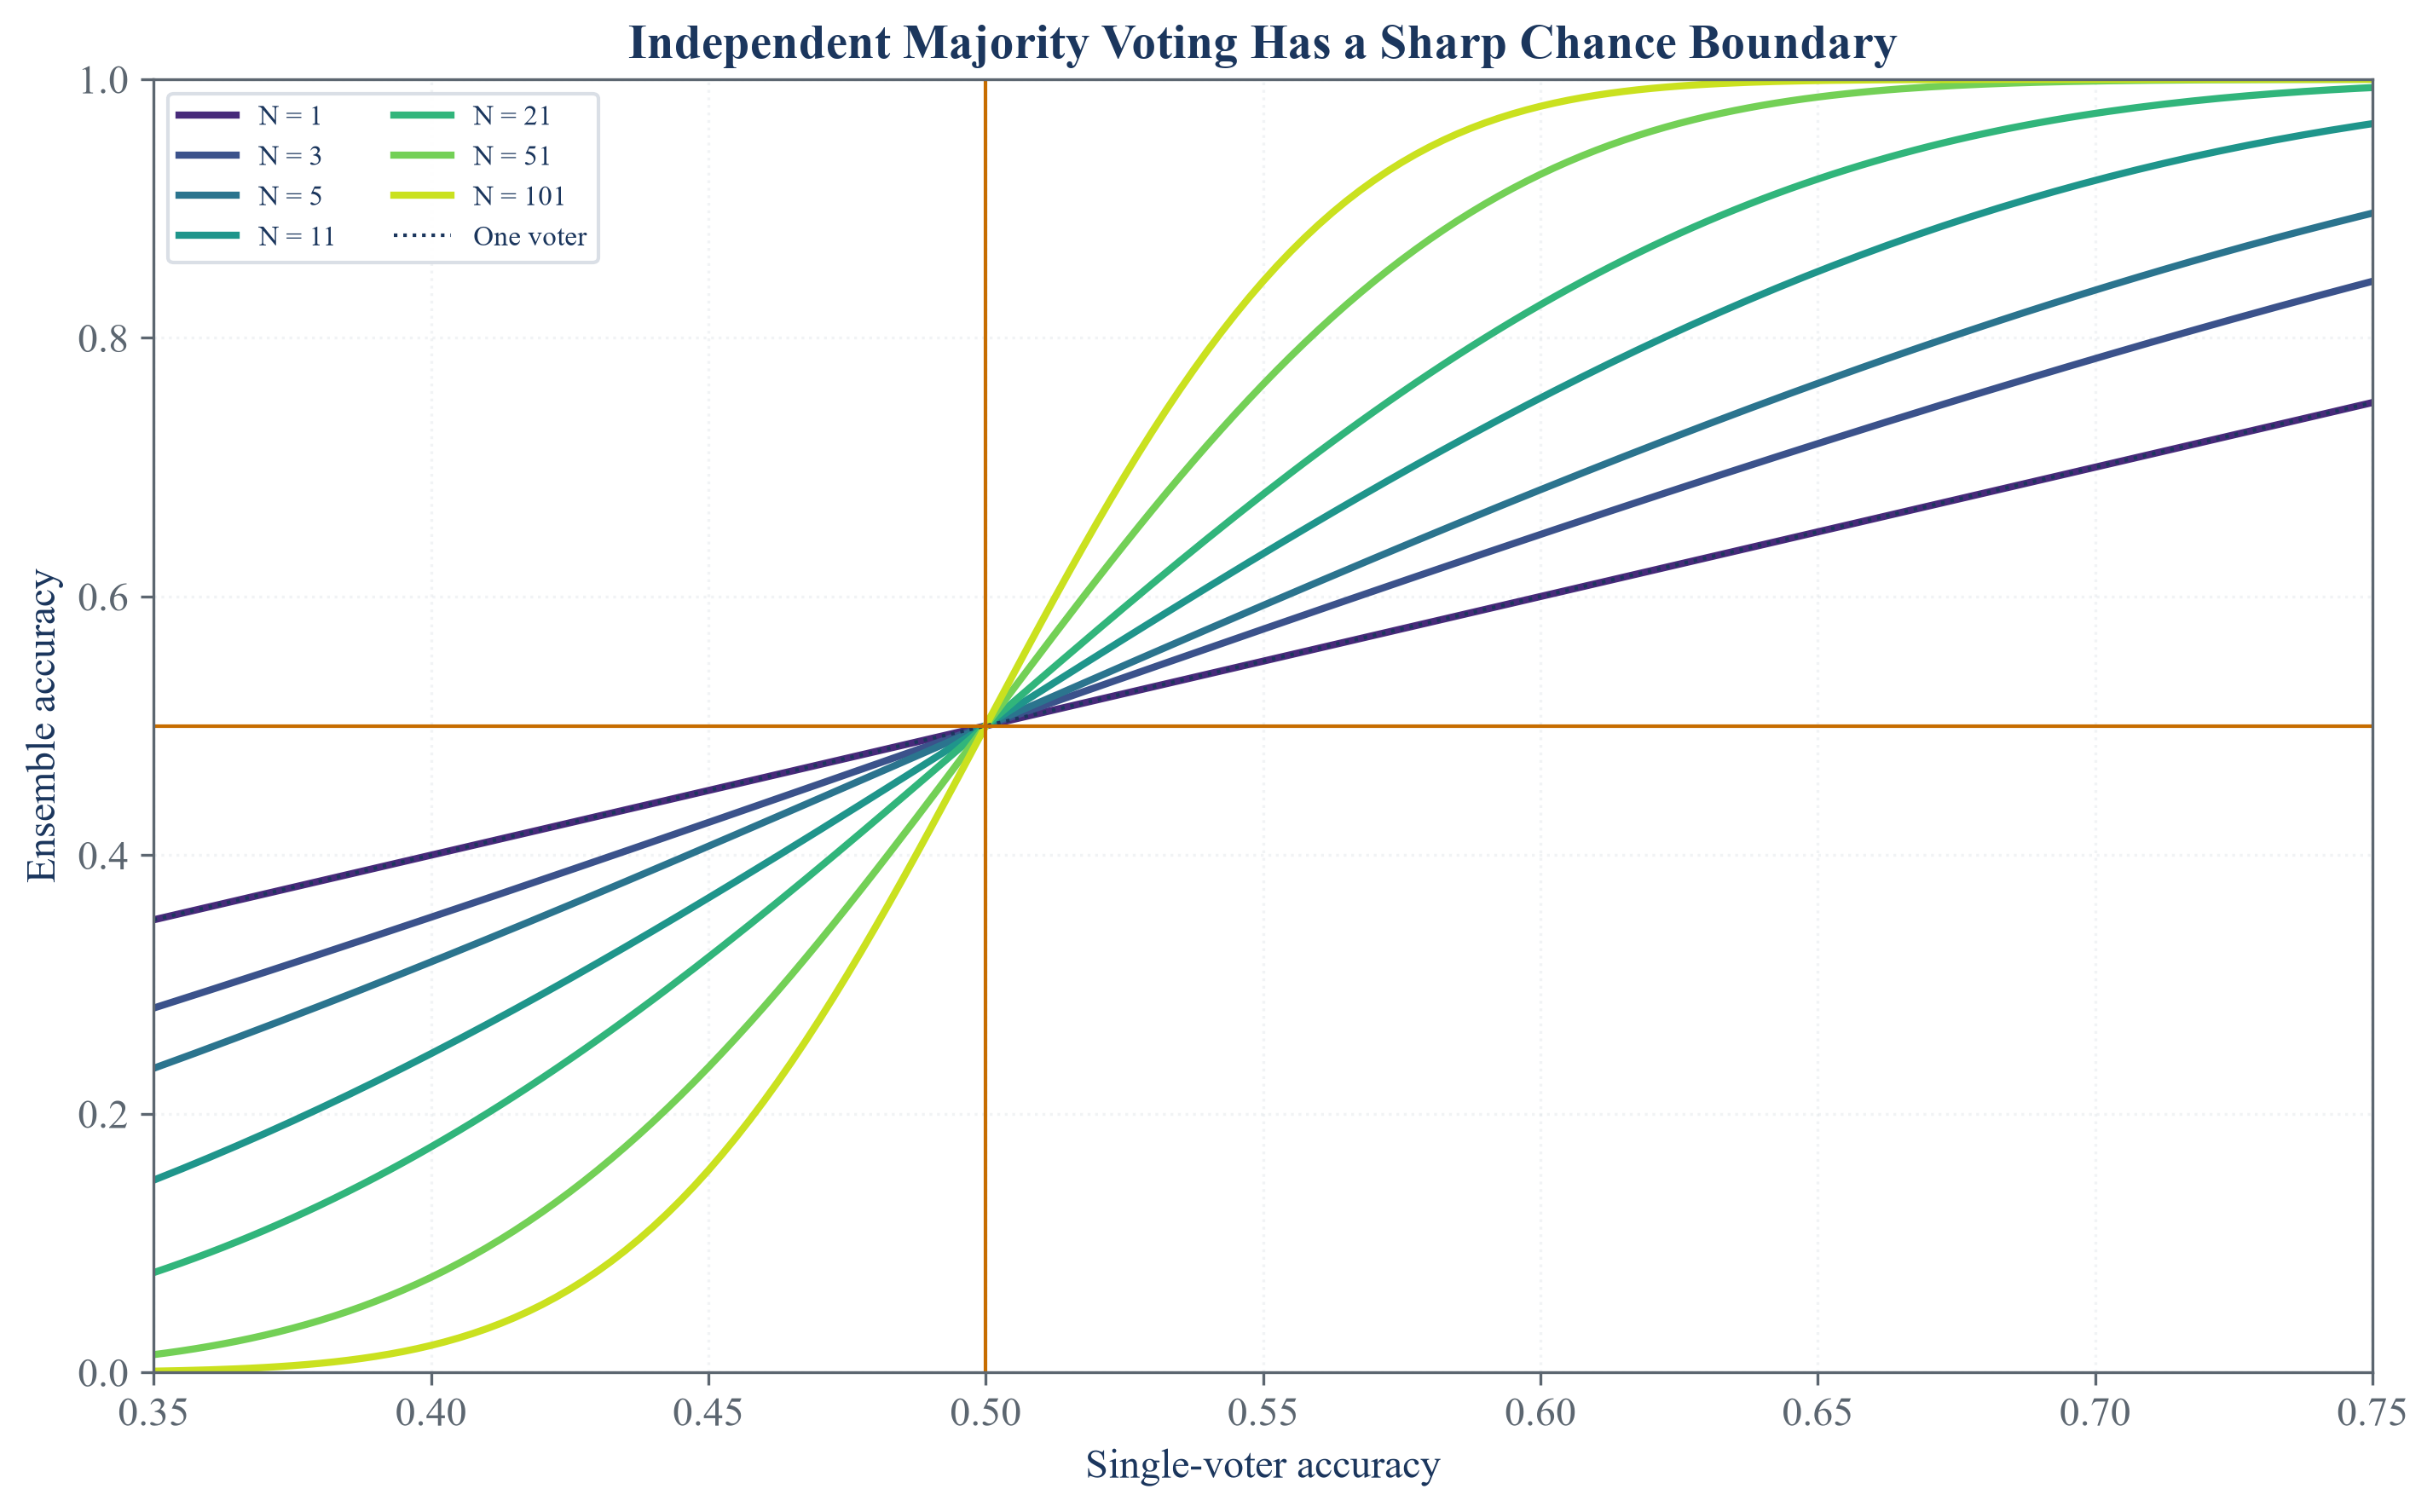

In [2]:
data_provenance = pd.DataFrame({
    "Field": ["Archive", "Provider", "Provider database vintage", "Return type", "Analysis start", "Analysis end", "Daily observations", "Industry portfolios", "Archive SHA256"],
    "Value": ["49_Industry_Portfolios_daily_CSV.zip", "Kenneth R. French Data Library", "202608 CRSP database", "Daily value-weighted return", str(industry_returns.index.min().date()), str(industry_returns.index.max().date()), f"{len(industry_returns):,}", str(industry_returns.shape[1]), data_hash],
})
save_table(data_provenance, "data_provenance", "Fixed public observations used in Chapter 13.", "tab:chapter13-data-provenance", fit=True)
display(data_provenance)

voter_counts = [1, 3, 5, 11, 21, 51, 101]
probability_grid = np.linspace(0.35, 0.75, 161)
independent_curves = pd.DataFrame([
    {"Voters": voters, "Single-voter accuracy": probability, "Ensemble accuracy": bagging_classifier_accuracy(voters, probability)}
    for voters in voter_counts for probability in probability_grid
])
reported_probabilities = [0.40, 0.50, 0.55, 0.60, 0.70]
independent_accuracy = pd.DataFrame([
    {"Voters": voters, "Single-voter accuracy": probability, "Ensemble accuracy": bagging_classifier_accuracy(voters, probability), "Change": bagging_classifier_accuracy(voters, probability) - probability}
    for voters in voter_counts for probability in reported_probabilities
])
independent_accuracy_display = independent_accuracy[independent_accuracy["Voters"].isin([1, 11, 101])].copy()
save_table(independent_accuracy_display, "independent_accuracy", "Independent majority-vote accuracy for selected voter counts and individual accuracies.", "tab:chapter13-independent-accuracy", fit=True)
display(independent_accuracy_display.round(6))

figure, axis = plt.subplots(figsize=(9.4, 5.8), constrained_layout=True)
colors = plt.cm.viridis(np.linspace(0.12, 0.92, len(voter_counts)))
for color, voters in zip(colors, voter_counts):
    current = independent_curves[independent_curves["Voters"] == voters]
    axis.plot(current["Single-voter accuracy"], current["Ensemble accuracy"], color=color, linewidth=2.0, label=f"N = {voters}")
axis.plot(probability_grid, probability_grid, color=palette["text"], linewidth=1.0, linestyle=":", label="One voter")
axis.axvline(0.5, color=palette["amber"], linewidth=1.0)
axis.axhline(0.5, color=palette["amber"], linewidth=1.0)
axis.set_title("Independent Majority Voting Has a Sharp Chance Boundary")
axis.set_xlabel("Single-voter accuracy")
axis.set_ylabel("Ensemble accuracy")
axis.set_xlim(0.35, 0.75)
axis.set_ylim(0.0, 1.0)
axis.grid(alpha=0.35)
axis.legend(ncol=2, fontsize=8)
figure.savefig(FIGURES / "independent_majority_accuracy.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "independent_majority_accuracy.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "independent_majority_accuracy.png")))
plt.close(figure)

Equal positive dependence leaves a common variance floor and makes $N$ voters behave like a smaller independent ensemble:

$$
\operatorname{Var}(\overline Z_N)
=\sigma^2\!\left(\rho+\frac{1-\rho}{N}\right),
\qquad
N_{\mathrm{eff}}=\frac{N}{1+(N-1)\rho}.
$$

Here, $Z_i$ is voter $i$'s numerical output; $\overline Z_N=N^{-1}\sum_i Z_i$ is their mean; $\sigma^2$ is each output's variance. $\rho$ is the common pairwise correlation; $N$ is the stated voter count; $N_{\mathrm{eff}}$ is the independent-equivalent count; $\operatorname{Var}$ denotes variance.

## How dependence reduces effective ensemble size

A shared random success chance creates exchangeable correct votes whose mean is $p$ and whose pairwise correlation is $\rho.$:

$$
\Theta\sim\operatorname{Beta}(\alpha,\beta),
\qquad
K\mid\Theta\sim\operatorname{Binomial}(N,\Theta),
\qquad
\alpha=p(\rho^{-1}-1),
\quad
\beta=(1-p)(\rho^{-1}-1).
$$

Here, $\Theta$ is the shared success chance for one repetition; $\operatorname{Beta}(\alpha,\beta)$ is its distribution; $\alpha,\beta$ are shape parameters. $K$ is the number of correct votes among $N$; $p$ is mean voter accuracy; $\rho\in(0,1)$ is correct-vote correlation; the case $\rho=0$ is simulated independently.

,Voters,Correct-vote correlation,Majority accuracy,Effective voters
0,1,0,0.597300,1
1,3,0,0.646100,3
2,5,0,0.681225,5
3,11,0,0.752850,11
4,21,0,0.824312,21
5,51,0,0.926150,51
6,101,0,0.978662,101
7,1,0.05,0.597312,1
8,3,0.05,0.641850,2.727273
9,5,0.05,0.672000,4.166667


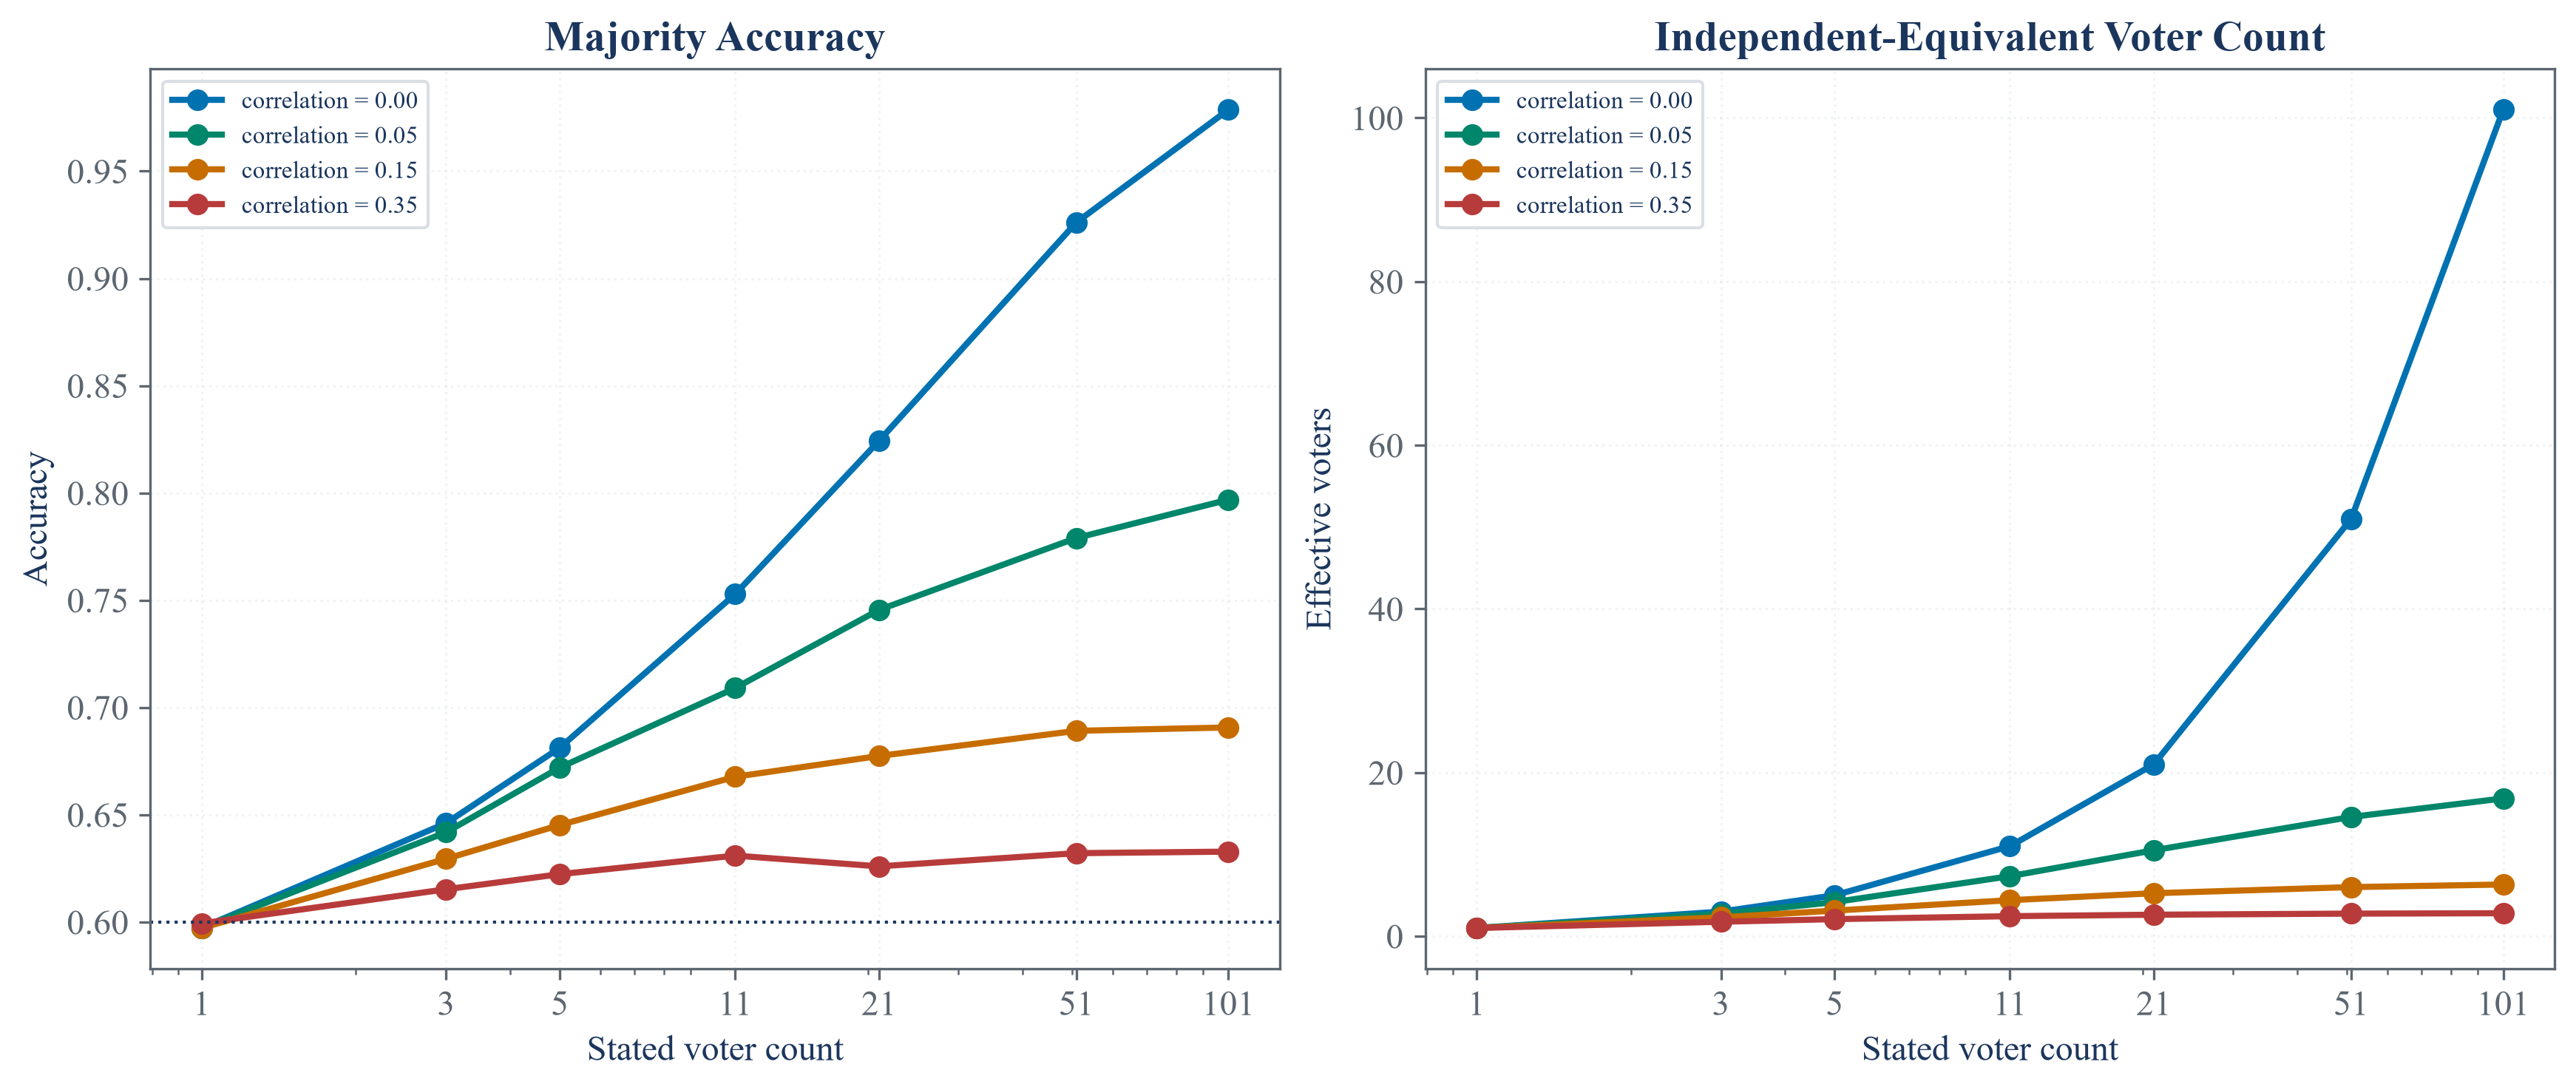

In [3]:
controlled_rng = np.random.default_rng(13001)
controlled_paths = 80000
controlled_p = 0.60
dependence_levels = [0.0, 0.05, 0.15, 0.35]
controlled_rows = []
for dependence in dependence_levels:
    for voters in voter_counts:
        if dependence == 0:
            correct_votes = controlled_rng.binomial(voters, controlled_p, controlled_paths)
        else:
            concentration = dependence ** -1 - 1
            shared_probability = controlled_rng.beta(controlled_p * concentration, (1 - controlled_p) * concentration, controlled_paths)
            correct_votes = controlled_rng.binomial(voters, shared_probability)
        measured_accuracy = np.mean(correct_votes > voters // 2)
        effective_count = voters / (1 + (voters - 1) * dependence)
        controlled_rows.append({"Voters": voters, "Correct-vote correlation": dependence, "Majority accuracy": measured_accuracy, "Effective voters": effective_count})
controlled_dependence = pd.DataFrame(controlled_rows)
save_table(controlled_dependence, "controlled_dependence", "Known-truth majority accuracy under exchangeable vote dependence.", "tab:chapter13-controlled-dependence", fit=True)
display(controlled_dependence.round(6))

figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), constrained_layout=True)
dependence_colors = [palette["cyan"], palette["green"], palette["amber"], palette["rose"]]
for color, dependence in zip(dependence_colors, dependence_levels):
    current = controlled_dependence[controlled_dependence["Correct-vote correlation"] == dependence]
    axes[0].plot(current["Voters"], current["Majority accuracy"], marker="o", color=color, linewidth=2.0, label=f"correlation = {dependence:.2f}")
    axes[1].plot(current["Voters"], current["Effective voters"], marker="o", color=color, linewidth=2.0, label=f"correlation = {dependence:.2f}")
axes[0].axhline(controlled_p, color=palette["text"], linestyle=":", linewidth=1.0)
axes[0].set_title("Majority Accuracy")
axes[0].set_xlabel("Stated voter count")
axes[0].set_ylabel("Accuracy")
axes[1].set_title("Independent-Equivalent Voter Count")
axes[1].set_xlabel("Stated voter count")
axes[1].set_ylabel("Effective voters")
for axis in axes:
    axis.set_xscale("log")
    axis.set_xticks(voter_counts, voter_counts)
    axis.grid(alpha=0.35)
    axis.legend(fontsize=8)
figure.savefig(FIGURES / "controlled_dependence_effect.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "controlled_dependence_effect.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "controlled_dependence_effect.png")))
plt.close(figure)

## Public Industry Voting

Each tree casts a signed binary vote, and the released calculation compares equal, training-accuracy, and $1-c_i^2$ weights:

$$
\begin{gathered}
\widehat y(x;w)
=\mathbf 1\!\left\{\sum_{i=1}^{N}w_i(2\widehat y_i(x)-1)>0\right\},
\qquad
\sum_{i=1}^{N}w_i=1,\\
w_i^{(u)}=\frac1N,
\qquad
w_i^{(c)}=\frac{c_i}{\sum_j c_j},
\qquad
w_i^{(v)}=\frac{1-c_i^2}{\sum_j(1-c_j^2)}.
\end{gathered}
$$

Here, $x$ is a feature vector; $\widehat y_i(x)\in\{0,1\}$ is tree $i$'s vote; $w_i$ is its nonnegative weight; $N$ is the number of trees. $\widehat y(x;w)$ is the combined prediction; $\mathbf 1\{\cdot\}$ is the indicator; $c_i$ is tree $i$'s training accuracy; superscripts $u,c,v$ name the three rules.

,Quantity,Value
0,Usable dates,1755
1,Predictors,12
2,Lookback days,5
3,Forecast step,1
4,Training dates,1228
5,Test dates,527
6,Training end,2023-11-22
7,Test start,2023-11-24
8,Positive target share,0.531624


,Weight rule,Test accuracy,Minimum weight,Maximum weight,Mean tree training accuracy,Mean correctness correlation,Effective trees
0,Uniform,0.502846,0.009901,0.009901,0.670881,0.021768,31.79261
1,Training accuracy,0.502846,0.009470,0.010275,0.670881,0.021768,31.79261
2,One minus squared accuracy,0.502846,0.009279,0.010593,0.670881,0.021768,31.79261


,Trees,Mean accuracy,Tenth percentile,Ninetieth percentile
0,1,0.500348,0.466414,0.527514
1,3,0.498039,0.472296,0.523719
2,5,0.494655,0.472296,0.518027
3,11,0.498419,0.476091,0.520114
4,21,0.496711,0.476091,0.518027
5,51,0.493707,0.472486,0.510436
6,101,0.502846,0.502846,0.502846


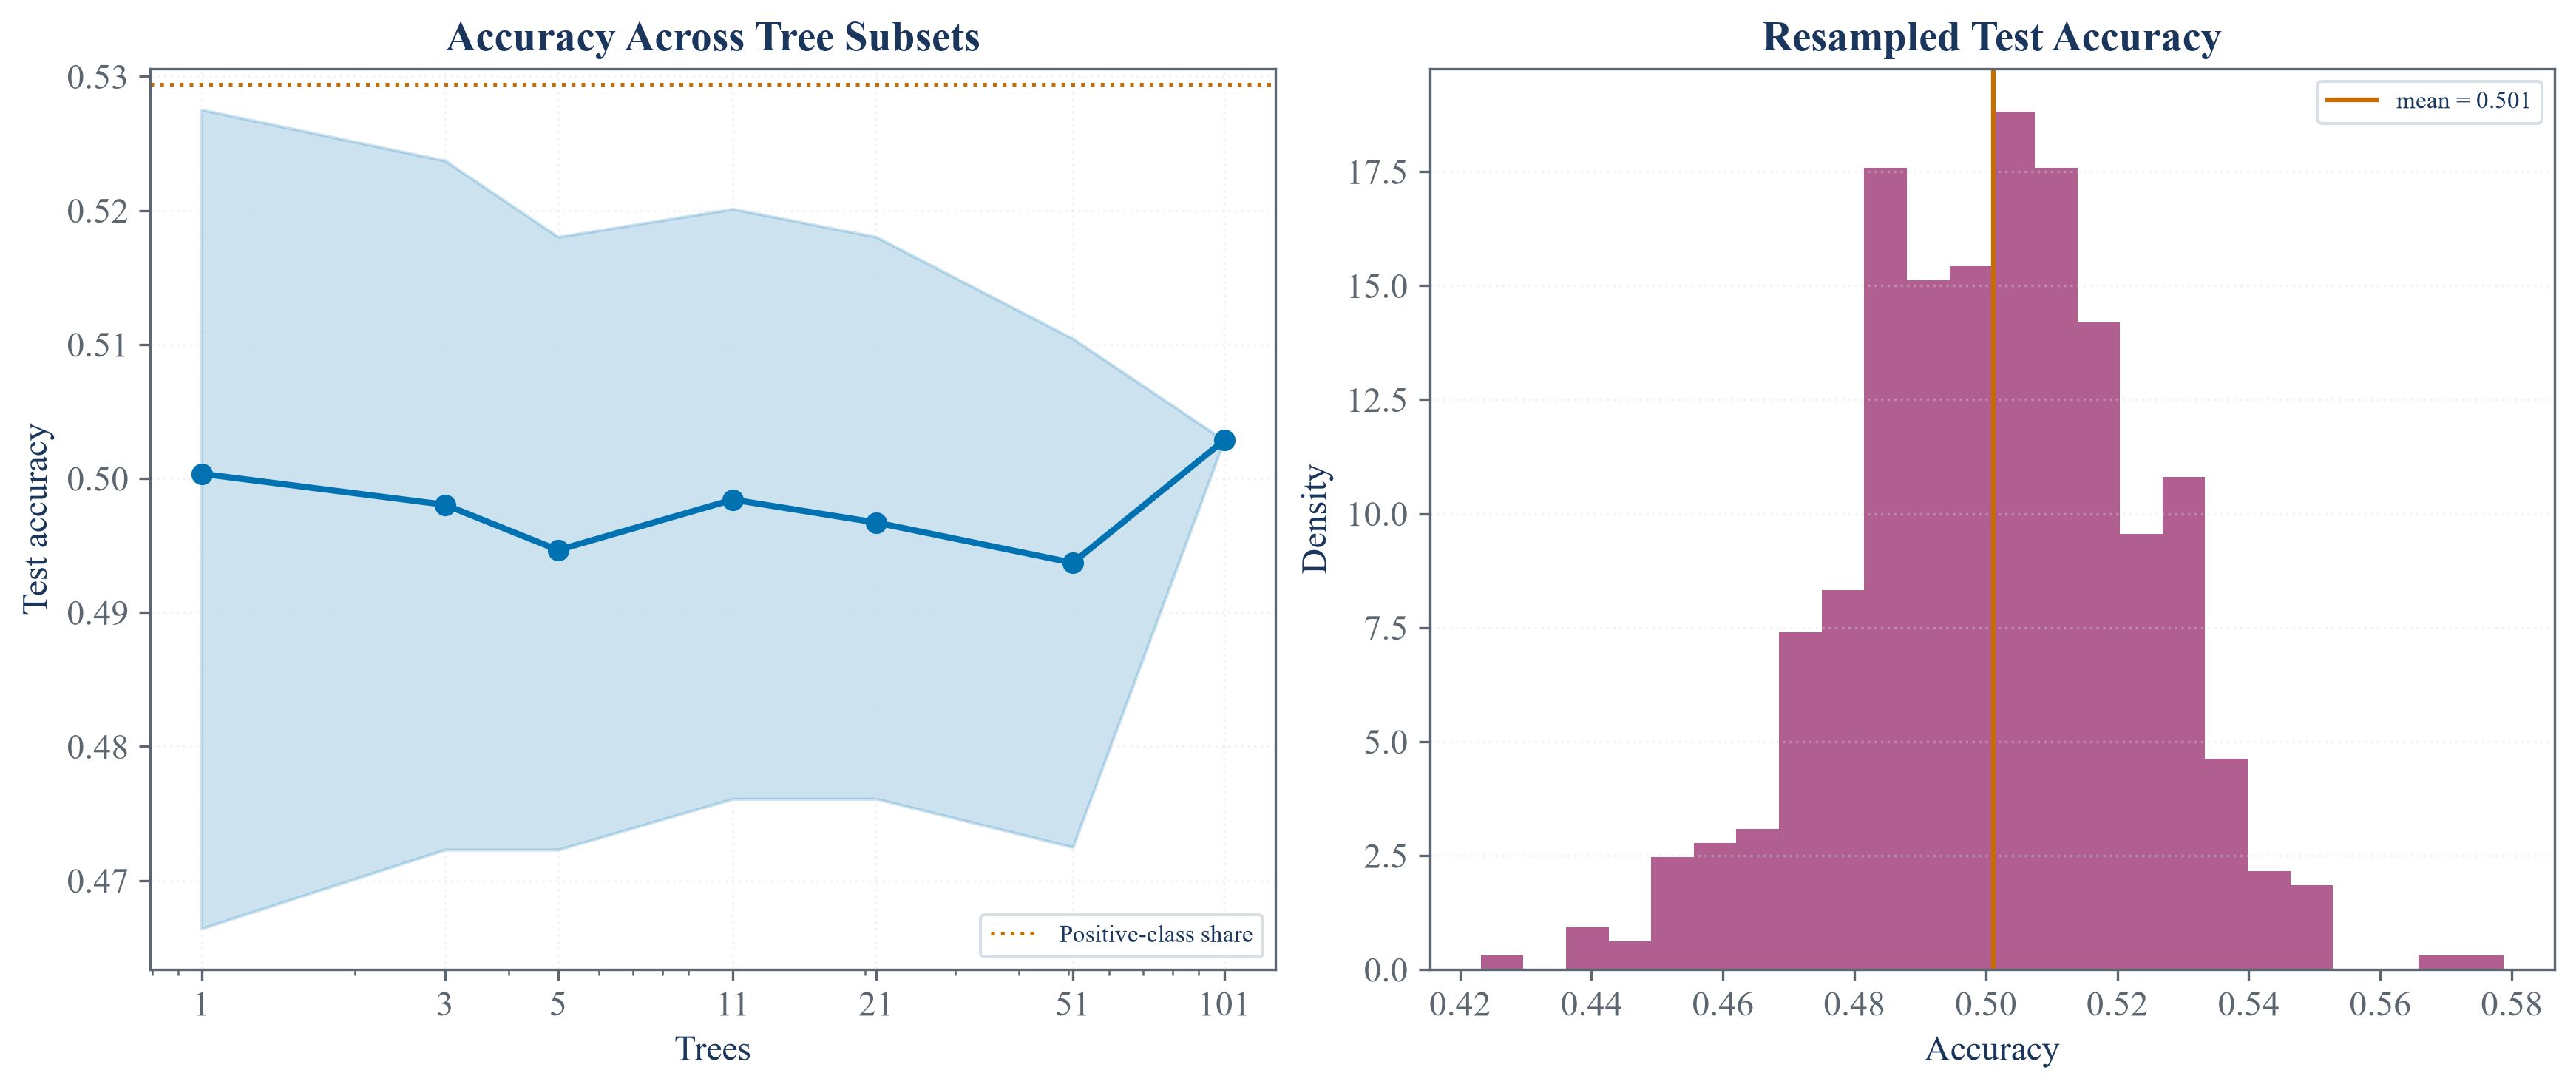

In [4]:
public_task_summary = pd.DataFrame({
    "Quantity": ["Usable dates", "Predictors", "Lookback days", "Forecast step", "Training dates", "Test dates", "Training end", "Test start", "Positive target share"],
    "Value": [len(public_x), public_x.shape[1], 5, 1, len(public_x_train), len(public_x_test), str(public_x_train.index.max().date()), str(public_x_test.index.min().date()), public_y.mean()],
})
save_table(public_task_summary, "public_task_summary", "Time-ordered public industry prediction task.", "tab:chapter13-public-task-summary", fit=False)
display(public_task_summary)

public_evaluator = BaggingClassifierAccuracy(n_estimators=101, max_samples=500, max_features=1.0, random_state=13011)
public_accuracies = public_evaluator.evaluate_all_schemes(public_x_test, public_y_test, public_x_train, public_y_train)
public_tree_predictions = np.column_stack([tree.predict(public_x_test) for tree in public_evaluator.estimators_])
public_tree_correct = (public_tree_predictions == public_y_test.to_numpy()[:, None]).astype(float)
correct_correlation = np.corrcoef(public_tree_correct, rowvar=False)
finite_pairwise = correct_correlation[np.triu_indices_from(correct_correlation, 1)]
finite_pairwise = finite_pairwise[np.isfinite(finite_pairwise)]
mean_correct_correlation = finite_pairwise.mean()
effective_public_trees = len(public_evaluator.estimators_) / (1 + (len(public_evaluator.estimators_) - 1) * mean_correct_correlation)

public_ensemble_summary = pd.DataFrame([
    {"Weight rule": "Uniform", "Test accuracy": public_accuracies["uniform"], "Minimum weight": public_evaluator.weights_["uniform"].min(), "Maximum weight": public_evaluator.weights_["uniform"].max()},
    {"Weight rule": "Training accuracy", "Test accuracy": public_accuracies["c_i"], "Minimum weight": public_evaluator.weights_["c_i"].min(), "Maximum weight": public_evaluator.weights_["c_i"].max()},
    {"Weight rule": "One minus squared accuracy", "Test accuracy": public_accuracies["variance"], "Minimum weight": public_evaluator.weights_["variance"].min(), "Maximum weight": public_evaluator.weights_["variance"].max()},
])
public_ensemble_summary["Mean tree training accuracy"] = public_evaluator.c_i_scores_.mean()
public_ensemble_summary["Mean correctness correlation"] = mean_correct_correlation
public_ensemble_summary["Effective trees"] = effective_public_trees
save_table(public_ensemble_summary, "public_ensemble_summary", "Public voting results and dependence summary.", "tab:chapter13-public-ensemble-summary", fit=True)
display(public_ensemble_summary.round(6))

curve_rng = np.random.default_rng(13012)
curve_rows = []
for voters in voter_counts:
    repeated_accuracy = []
    for repetition in range(60):
        chosen = curve_rng.permutation(public_tree_predictions.shape[1])[:voters]
        majority = (public_tree_predictions[:, chosen].sum(axis=1) > voters // 2).astype(int)
        repeated_accuracy.append(accuracy_score(public_y_test, majority))
    curve_rows.append({"Trees": voters, "Mean accuracy": np.mean(repeated_accuracy), "Tenth percentile": np.quantile(repeated_accuracy, 0.10), "Ninetieth percentile": np.quantile(repeated_accuracy, 0.90)})
public_ensemble_curve = pd.DataFrame(curve_rows)
save_table(public_ensemble_curve, "public_ensemble_curve", "Public uniform-vote accuracy over repeated subsets of fitted trees.", "tab:chapter13-public-ensemble-curve", fit=False)
display(public_ensemble_curve.round(6))

np.random.seed(13013)
bootstrap_accuracy, bootstrap_mean, bootstrap_std = calculate_bootstrap_accuracy(public_evaluator.clf, public_x_test, public_y_test, n_bootstraps=500)

figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), constrained_layout=True)
axes[0].plot(public_ensemble_curve["Trees"], public_ensemble_curve["Mean accuracy"], color=palette["cyan"], marker="o", linewidth=2.0)
axes[0].fill_between(public_ensemble_curve["Trees"], public_ensemble_curve["Tenth percentile"], public_ensemble_curve["Ninetieth percentile"], color=palette["cyan"], alpha=0.20)
axes[0].axhline(public_y_test.mean(), color=palette["amber"], linestyle=":", linewidth=1.2, label="Positive-class share")
axes[0].set_xscale("log")
axes[0].set_xticks(voter_counts, voter_counts)
axes[0].set_title("Accuracy Across Tree Subsets")
axes[0].set_xlabel("Trees")
axes[0].set_ylabel("Test accuracy")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.35)
axes[1].hist(bootstrap_accuracy, bins=24, density=True, color=palette["violet"], alpha=0.82)
axes[1].axvline(bootstrap_mean, color=palette["amber"], linewidth=1.5, label=f"mean = {bootstrap_mean:.3f}")
axes[1].set_title("Resampled Test Accuracy")
axes[1].set_xlabel("Accuracy")
axes[1].set_ylabel("Density")
axes[1].legend(fontsize=8)
axes[1].grid(axis="y", alpha=0.35)
figure.savefig(FIGURES / "public_bagging_accuracy.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "public_bagging_accuracy.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "public_bagging_accuracy.png")))
plt.close(figure)

## Individual Tree Accuracy

The training accuracy of one tree is the share of training observations it classifies correctly:

$$
c_i=\frac{1}{T}\sum_{t=1}^{T}\mathbf 1\{\widehat y_{i,t}=y_t\}.
$$

Here, $i$ identifies a tree; $t$ identifies a training observation; $T$ is the training sample size. $\widehat y_{i,t}$ is tree $i$'s prediction for observation $t$; $y_t$ is the observed class; $\mathbf 1\{\cdot\}$ equals one when the prediction is correct; $c_i$ is tree accuracy.

,Summary,Training accuracy
0,Smallest,0.641694
1,10th percentile,0.655537
2,25th percentile,0.664495
3,Middle value,0.670195
4,Mean,0.670881
5,75th percentile,0.679153
6,90th percentile,0.685668
7,Largest,0.696254
8,Standard deviation,0.011814


,Group,Tree number,Training accuracy
0,Five smallest,33,0.641694
1,Five smallest,1,0.642508
2,Five smallest,28,0.645765
3,Five smallest,15,0.645765
4,Five smallest,51,0.648208
5,Five largest,21,0.691368
6,Five largest,17,0.692182
7,Five largest,99,0.692997
8,Five largest,87,0.693811
9,Five largest,78,0.696254


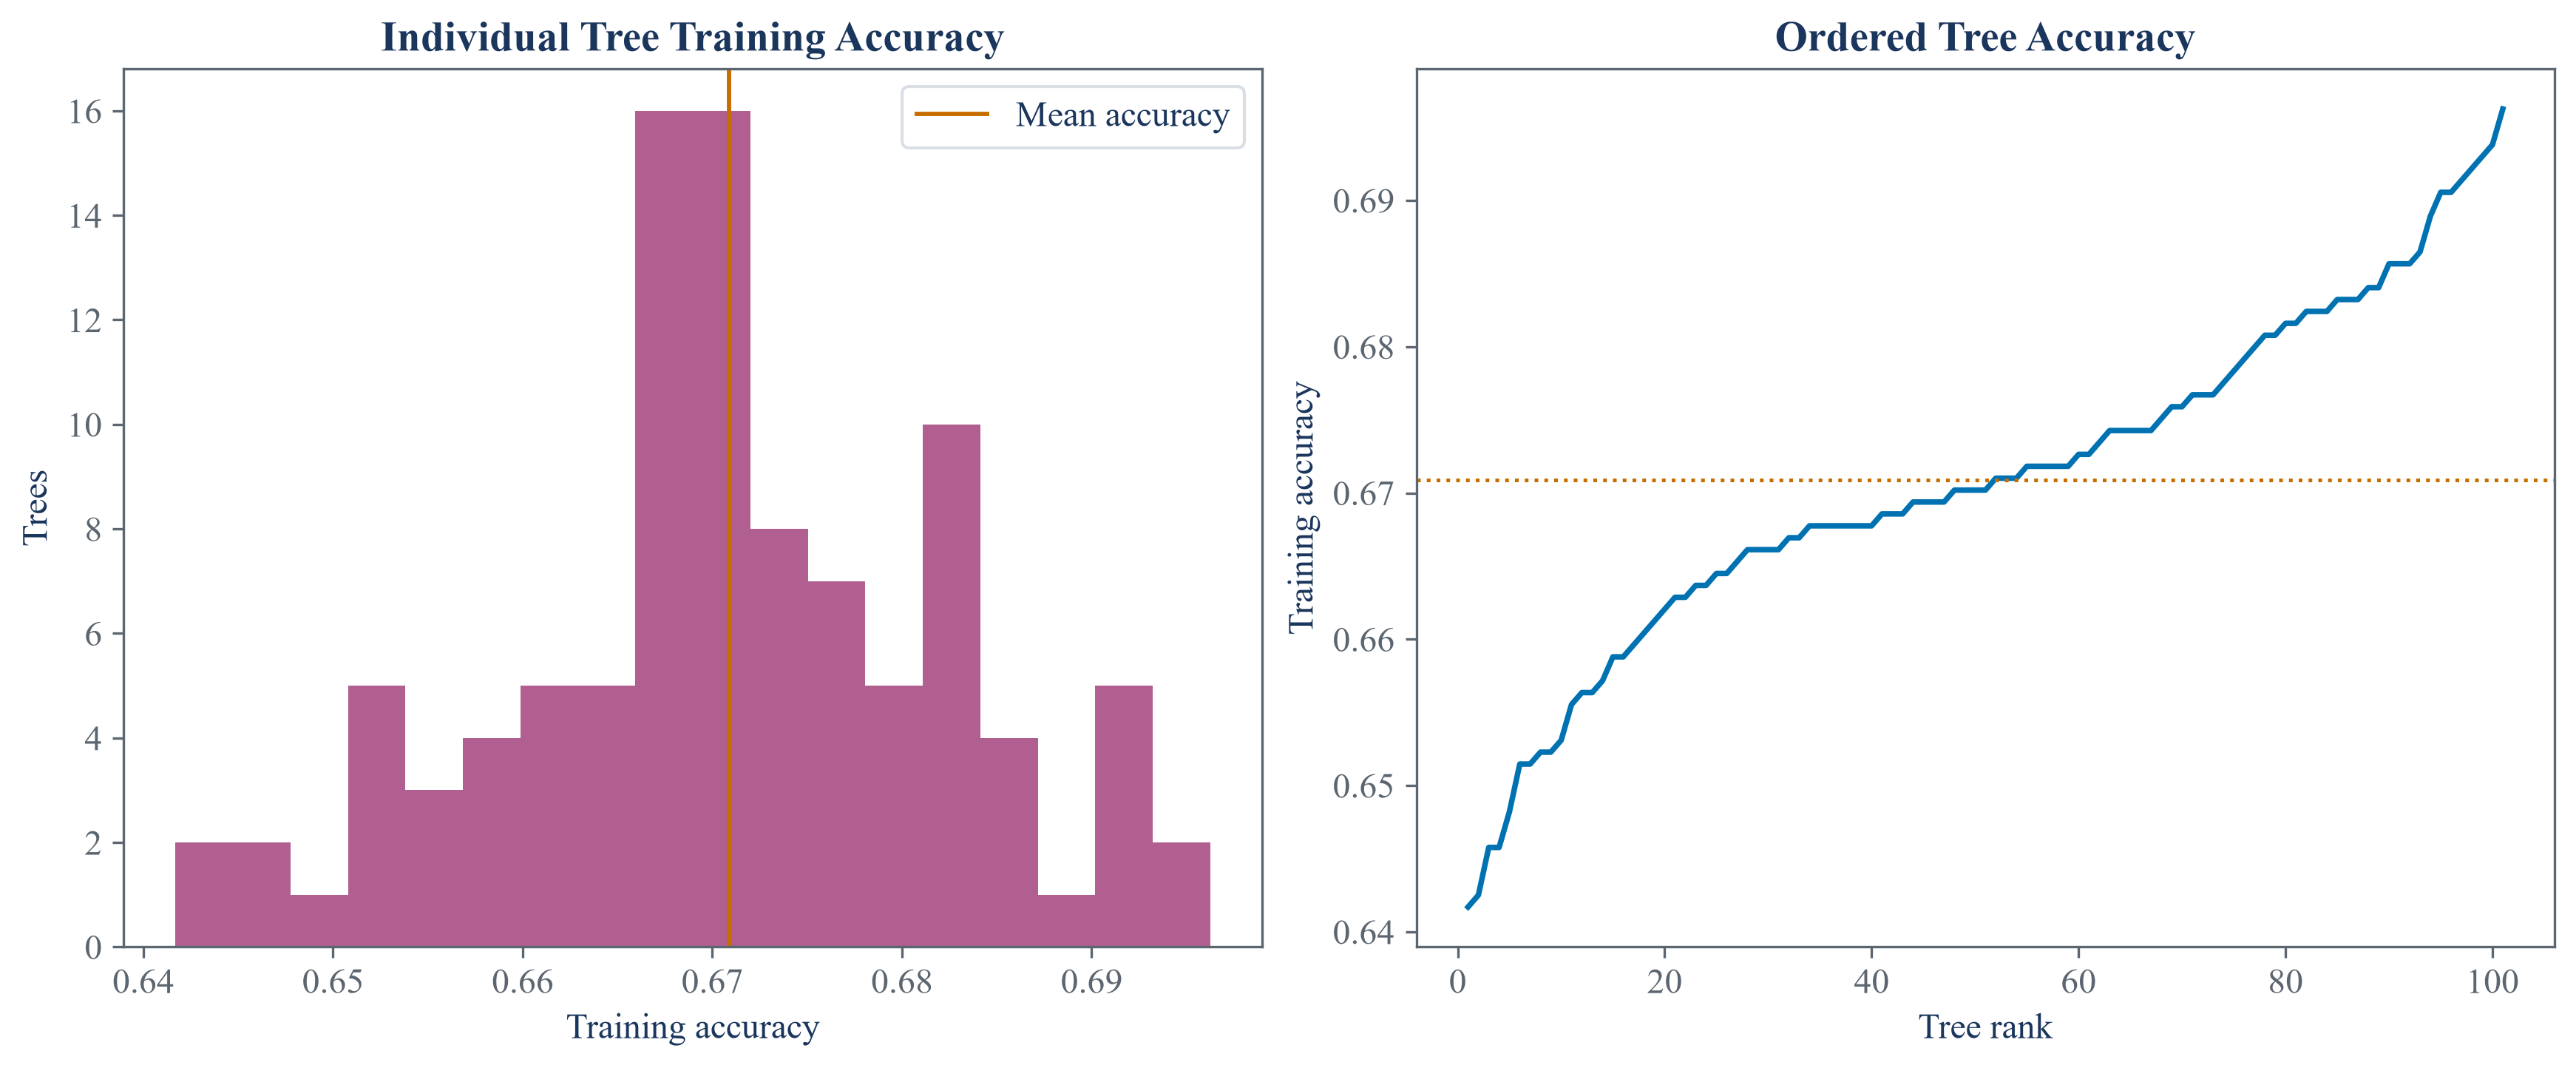

In [5]:
tree_training_accuracy = pd.Series(public_evaluator.c_i_scores_, name="Training accuracy")
tree_accuracy_summary = pd.DataFrame({
    "Summary": ["Smallest", "10th percentile", "25th percentile", "Middle value", "Mean", "75th percentile", "90th percentile", "Largest", "Standard deviation"],
    "Training accuracy": [tree_training_accuracy.min(), tree_training_accuracy.quantile(0.10), tree_training_accuracy.quantile(0.25), tree_training_accuracy.median(), tree_training_accuracy.mean(), tree_training_accuracy.quantile(0.75), tree_training_accuracy.quantile(0.90), tree_training_accuracy.max(), tree_training_accuracy.std(ddof=1)],
})
ranked_tree_accuracy = tree_training_accuracy.sort_values().reset_index()
ranked_tree_accuracy.columns = ["Tree number", "Training accuracy"]
ranked_tree_accuracy["Tree number"] = ranked_tree_accuracy["Tree number"] + 1
tree_accuracy_extremes = pd.concat([ranked_tree_accuracy.head(5).assign(Group="Five smallest"), ranked_tree_accuracy.tail(5).assign(Group="Five largest")], ignore_index=True)[["Group", "Tree number", "Training accuracy"]]
save_table(tree_accuracy_summary, "tree_training_accuracy_summary", "Distribution of individual-tree training accuracy.", "tab:chapter13-tree-training-accuracy", fit=False)
save_table(tree_accuracy_extremes, "tree_training_accuracy_extremes", "Trees with the five smallest and five largest training accuracies.", "tab:chapter13-tree-training-accuracy-extremes", fit=False)
display(tree_accuracy_summary.round(6))
display(tree_accuracy_extremes.round(6))

figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.7), constrained_layout=True)
axes[0].hist(tree_training_accuracy, bins=18, color=palette["violet"], alpha=0.82)
axes[0].axvline(tree_training_accuracy.mean(), color=palette["amber"], linewidth=1.4, label="Mean accuracy")
axes[0].set_title("Individual Tree Training Accuracy")
axes[0].set_xlabel("Training accuracy")
axes[0].set_ylabel("Trees")
axes[0].legend()
axes[1].plot(np.arange(1, len(ranked_tree_accuracy) + 1), ranked_tree_accuracy["Training accuracy"], color=palette["cyan"], linewidth=1.8)
axes[1].axhline(tree_training_accuracy.mean(), color=palette["amber"], linewidth=1.2, linestyle=":")
axes[1].set_title("Ordered Tree Accuracy")
axes[1].set_xlabel("Tree rank")
axes[1].set_ylabel("Training accuracy")
figure.savefig(FIGURES / "tree_training_accuracy.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "tree_training_accuracy.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "tree_training_accuracy.png")))
plt.close(figure)

## Tests

In [6]:
assert data_hash == EXPECTED_DATA_HASH
assert industry_returns.shape == (1760, 49)
assert public_x.shape == (1755, 12)
assert len(public_x_train) == 1228
assert len(public_x_test) == 527
assert public_x_train.index.max() < public_x_test.index.min()
assert public_y.isin([0, 1]).all()
assert np.isclose(bagging_classifier_accuracy(1, 0.70), 0.70)
assert np.isclose(bagging_classifier_accuracy(3, 0.70), 0.784)
assert np.isclose(bagging_classifier_accuracy(101, 0.50), 0.50)
assert bagging_classifier_accuracy(101, 0.60) > 0.97
assert bagging_classifier_accuracy(101, 0.40) < 0.03
assert independent_accuracy.shape == (35, 4)
assert controlled_dependence.shape == (28, 4)
assert controlled_dependence["Majority accuracy"].between(0, 1).all()
assert controlled_dependence["Effective voters"].ge(1).all()
assert controlled_dependence.query("`Correct-vote correlation` == 0 and Voters == 101")["Majority accuracy"].item() > 0.97
assert controlled_dependence.query("`Correct-vote correlation` == 0.35 and Voters == 101")["Majority accuracy"].item() < 0.70
assert controlled_dependence.query("`Correct-vote correlation` == 0.35 and Voters == 101")["Effective voters"].item() < 3.0
assert set(public_accuracies) == {"uniform", "c_i", "variance"}
assert all(0 <= value <= 1 for value in public_accuracies.values())
assert public_tree_predictions.shape == (527, 101)
assert public_evaluator.c_i_scores_.shape == (101,)
assert all(np.isclose(weights.sum(), 1.0) for weights in public_evaluator.weights_.values())
assert np.isfinite(mean_correct_correlation)
assert 0 < effective_public_trees <= 101
assert public_ensemble_summary.shape == (3, 7)
assert public_ensemble_curve.shape == (7, 4)
assert np.all(public_ensemble_curve["Tenth percentile"] <= public_ensemble_curve["Mean accuracy"] + 1e-12)
assert np.all(public_ensemble_curve["Mean accuracy"] <= public_ensemble_curve["Ninetieth percentile"] + 1e-12)
assert len(tree_training_accuracy) == 101
assert tree_training_accuracy.between(0.0, 1.0).all()
assert tree_accuracy_summary.shape == (9, 2)
assert tree_accuracy_extremes.shape == (10, 3)
assert ranked_tree_accuracy["Training accuracy"].is_monotonic_increasing
assert bootstrap_accuracy.shape == (500,)
assert np.isclose(bootstrap_accuracy.mean(), bootstrap_mean)
assert bootstrap_std > 0
assert (FIGURES / "independent_majority_accuracy.pdf").is_file()
assert (FIGURES / "controlled_dependence_effect.pdf").is_file()
assert (FIGURES / "public_bagging_accuracy.pdf").is_file()
assert (FIGURES / "tree_training_accuracy.pdf").is_file()
assert (TABLES / "data_provenance.tex").is_file()
assert (TABLES / "independent_accuracy.tex").is_file()
assert (TABLES / "controlled_dependence.tex").is_file()
assert (TABLES / "public_ensemble_summary.tex").is_file()
assert (TABLES / "public_ensemble_curve.tex").is_file()
assert (TABLES / "tree_training_accuracy_summary.tex").is_file()
assert (TABLES / "tree_training_accuracy_extremes.tex").is_file()